# Checkpoint 3: Exploratory Data Analysis

Krish: sections 1, 2, plot 3 and 7. Mahi: Twitter distributions and plot 1. Dravya: FakeNewsNet/Facebook distributions and plot 2.

## 0. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 12   # readable axis labels

twitter_daily = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/figure_1/data/daily_counts_exposures.csv")
twitter_sites = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/coexposure_network/data/total_exposure_counts.csv")

fake = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_fake.csv")
real = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_real.csv")
fake["label"] = "fake"
real["label"] = "real"
news = pd.concat([fake, real], ignore_index=True)

facebook = pd.read_csv("https://raw.githubusercontent.com/BuzzFeedNews/2016-10-facebook-fact-check/master/data/facebook-fact-check.csv")
ratings = pd.read_csv("https://raw.githubusercontent.com/hauselin/domain-quality-ratings/main/data/domain_pc1.csv")

## 1. Dataset profiles
We used pandas, so `info()` is our version of `glimpse()` and `isna().sum()` is our version of `null_count()`.

### Primary 1a: Twitter daily counts

In [2]:
print(twitter_daily.shape)
twitter_daily.info()

(128, 10)
<class 'pandas.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ts_rel_days  128 non-null    int64  
 1   red          128 non-null    int64  
 2   orange       128 non-null    int64  
 3   black        128 non-null    int64  
 4   N            128 non-null    int64  
 5   date         128 non-null    str    
 6   pct_red      128 non-null    float64
 7   pct_orange   128 non-null    float64
 8   pct_black    128 non-null    float64
 9   pct_fake     128 non-null    float64
dtypes: float64(4), int64(5), str(1)
memory usage: 11.4 KB


In [3]:
twitter_daily.isna().sum()

ts_rel_days    0
red            0
orange         0
black          0
N              0
date           0
pct_red        0
pct_orange     0
pct_black      0
pct_fake       0
dtype: int64

In [4]:
twitter_daily.describe()

,ts_rel_days,red,orange,black,N,pct_red,pct_orange,pct_black,pct_fake
count,128.000000,128.000000,128.000000,128.000000,1.280000e+02,128.000000,128.000000,128.000000,128.000000
mean,-35.500000,11984.835938,9164.320312,3286.625000,4.934006e+05,0.025440,0.019494,0.007043,0.051978
std,37.094474,3820.934469,2793.924308,1363.460621,1.931745e+05,0.006002,0.004606,0.002681,0.012315
min,-99.000000,6390.000000,4250.000000,1315.000000,2.383320e+05,0.009457,0.008363,0.001411,0.019231
25%,-67.250000,8950.250000,7196.000000,2219.500000,3.852392e+05,0.021752,0.016302,0.005028,0.044212
50%,-35.500000,10801.500000,8735.500000,2683.000000,4.507975e+05,0.025368,0.019337,0.006466,0.051489
75%,-3.750000,13439.750000,10288.000000,4259.500000,5.718202e+05,0.029434,0.022525,0.008514,0.059443
max,28.000000,20738.000000,17813.000000,6110.000000,1.514602e+06,0.045792,0.032337,0.013770,0.082507


**What stands out:** No missing values. `date` is text instead of a date, so we fix that in section 2. The busiest days were Nov 8 and 9 (election day and the day after) with about 1.5 million views. `pct_fake` is between 1.9% and 8.3%, average 5.2%, so fake news was a small part of what people saw every day.

### Primary 1b: Twitter website totals

In [5]:
print(twitter_sites.shape)
twitter_sites.info()

(606, 2)
<class 'pandas.DataFrame'>
RangeIndex: 606 entries, 0 to 605
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   website  606 non-null    str  
 1   N        606 non-null    int64
dtypes: int64(1), str(1)
memory usage: 18.0 KB


In [6]:
twitter_sites.isna().sum()

website    0
N          0
dtype: int64

In [7]:
twitter_sites.describe()

,N
count,6.060000e+02
mean,7.079508e+04
std,2.540429e+05
min,4.700000e+01
25%,2.331750e+03
50%,7.701000e+03
75%,3.011975e+04
max,3.404953e+06


**What stands out:** No missing values or repeated websites. `N` is very skewed: the mean is about 70,800 but the median is only about 7,700, because a few sites like nytimes.com (3.4 million) are way bigger than the rest. We will need a log scale to plot it.

### Primary 2: FakeNewsNet (PolitiFact)

In [8]:
print(news.shape)
news.info()

(1056, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         1056 non-null   str  
 1   news_url   995 non-null    str  
 2   title      1056 non-null   str  
 3   tweet_ids  801 non-null    str  
 4   label      1056 non-null   str  
dtypes: str(5)
memory usage: 11.1 MB


In [9]:
news.isna().sum()

id             0
news_url      61
title          0
tweet_ids    255
label          0
dtype: int64

In [10]:
# number of tweets that shared each article
news["num_tweets"] = news["tweet_ids"].str.split().str.len()
news.describe()

,num_tweets
count,801.000000
mean,728.484395
std,2415.379702
min,1.000000
25%,14.000000
50%,84.000000
75%,486.000000
max,29060.000000


In [11]:
news.groupby("label")["num_tweets"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,392.0,421.816327,1810.121786,1.0,23.75,102.0,326.0,29060.0
real,409.0,1022.405868,2849.974457,1.0,8.00,58.0,929.0,27377.0


**What stands out:** 255 articles have no tweets and 61 have no URL. `num_tweets` is very skewed (max 29,060). The surprising part: fake articles have a higher median than real ones (102 vs 58) but a lower mean (422 vs 1,022), so whether fake news "spreads more" depends on which one we look at. Also, some titles didn't look like news at all, which we look at in section 2.

## 2. Anomalies

| Dataset | Problem | Rows | What we did |
|---|---|---|---|
| Twitter daily | `date` is text, not a date | 128 | fixed with `pd.to_datetime` |
| Twitter daily | checked for missing days / wrong percentages | 0 | none found |
| Twitter sites | 72 sites don't match the ratings (mostly subdomains like motto.time.com) | 72 | left it, only 1.6% of views |
| FakeNewsNet | same id labeled both fake and real | 4 | dropped |
| FakeNewsNet | not real articles ("Account Suspended", "website is for sale", MSN homepage) | 20 | dropped |
| FakeNewsNet | no tweet ids | 255 | set num_tweets to 0 |
| FakeNewsNet | missing url | 61 | left it, we don't need url right now |
| FakeNewsNet | urls in different formats (no http, web.archive.org links) | 80 + 196 | left it, matters only if we join on url later |
| FakeNewsNet | very big tweet counts (up to 29,060) | a few | kept them, but we use medians and log scale |

In [12]:
# Anomaly 1: date stored as text -> datetime
twitter_daily["date"] = pd.to_datetime(twitter_daily["date"])
twitter_daily = twitter_daily.sort_values("date")

# Anomaly 2: check for missing days, and that pct_fake matches the counts
all_days = pd.date_range(twitter_daily["date"].min(), twitter_daily["date"].max())
print("missing days:", len(all_days) - twitter_daily["date"].nunique())
check = (twitter_daily["red"] + twitter_daily["orange"] + twitter_daily["black"]) / twitter_daily["N"]
print("rows where pct_fake doesn't match:", ((check - twitter_daily["pct_fake"]).abs() > 0.000001).sum())

missing days: 0
rows where pct_fake doesn't match: 0


In [13]:
# Anomaly 3: Twitter websites with no quality rating
no_rating = twitter_sites[~twitter_sites["website"].isin(ratings["domain"])]
print(len(no_rating), "sites have no rating")
print("share of all views:", round(no_rating["N"].sum() / twitter_sites["N"].sum() * 100, 1), "%")
no_rating.sort_values("N", ascending=False).head()

72 sites have no rating
share of all views: 1.6 %


,website,N
414,twentytwowords.com,170691
467,tacticalinvestor.com,70993
380,motto.time.com,42146
323,1.001.free.fr,41501
157,lawnewz.com,28214


In [14]:
# Anomaly 4: same id labeled both fake and real
dup_ids = news[news["id"].duplicated(keep=False)]
print(len(dup_ids), "rows")
dup_ids[["id", "label", "title"]]

4 rows


,id,label,title
42,politifact14940,fake,Full text: Jeff Flake on Trump speech transcript
309,politifact14920,fake,eCFR — Code of Federal Regulations
519,politifact14940,real,Full text: Jeff Flake on Trump speech transcript
881,politifact14920,real,eCFR — Code of Federal Regulations


In [15]:
# Anomaly 5: junk pages that aren't news articles
junk_words = "Account Suspended|under construction|for sale|Outlook, Office, Skype"
junk = news["title"].str.contains(junk_words, case=False)
print(junk.sum(), "junk rows")
news.loc[junk, "title"].value_counts()

20 junk rows


title
Outlook, Office, Skype, Bing, Breaking News, and Latest Videos                                     13
Account Suspended                                                                                   3
American News is under construction                                                                 2
UsPostman.com is for sale (Us Postman)                                                              1
trueamericans.me -&nbspThis website is for sale! -&nbsptrueamericans Resources and Information.     1
Name: count, dtype: int64

In [16]:
# Cleaning: drop anomalies 4 and 5, fix anomaly 6
news_clean = news[~news["id"].isin(dup_ids["id"]) & ~junk].copy()
news_clean["num_tweets"] = news_clean["num_tweets"].fillna(0)

print("before:", news.shape, " after:", news_clean.shape)
news_clean["label"].value_counts()

before: (1056, 6)  after: (1032, 6)


label
real    609
fake    423
Name: count, dtype: int64

In [17]:
# Anomalies 7 and 8: flagged, not fixed
print("missing url:", news_clean["news_url"].isna().sum())
print("url without http:", (~news_clean["news_url"].dropna().str.startswith("http")).sum())
print("web.archive.org url:", news_clean["news_url"].dropna().str.contains("web.archive.org").sum())

missing url: 61
url without http: 80
web.archive.org url: 196


## 3. Distributions

### Twitter (Mahi)


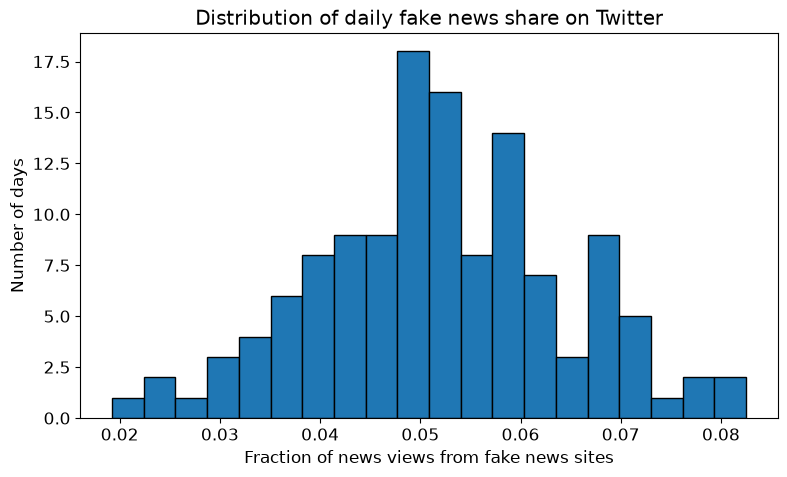

In [18]:

# Mahi: pct_fake histogram
plt.figure(figsize=(9, 5))
plt.hist(twitter_daily['pct_fake'], bins=20, edgecolor='black')
plt.title('Distribution of daily fake news share on Twitter')
plt.xlabel('Fraction of news views from fake news sites')
plt.ylabel('Number of days')
plt.show()

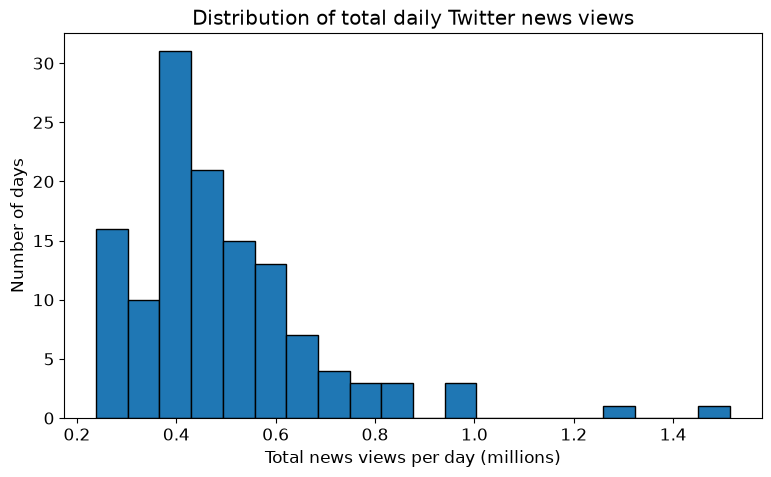

In [19]:
# Mahi: N histogram
plt.figure(figsize=(9, 5))
plt.hist(twitter_daily['N'] / 1000000, bins=20, edgecolor='black')
plt.title('Distribution of total daily Twitter news views')
plt.xlabel('Total news views per day (millions)')
plt.ylabel('Number of days')
plt.show()


### FakeNewsNet and Facebook (Dravya)


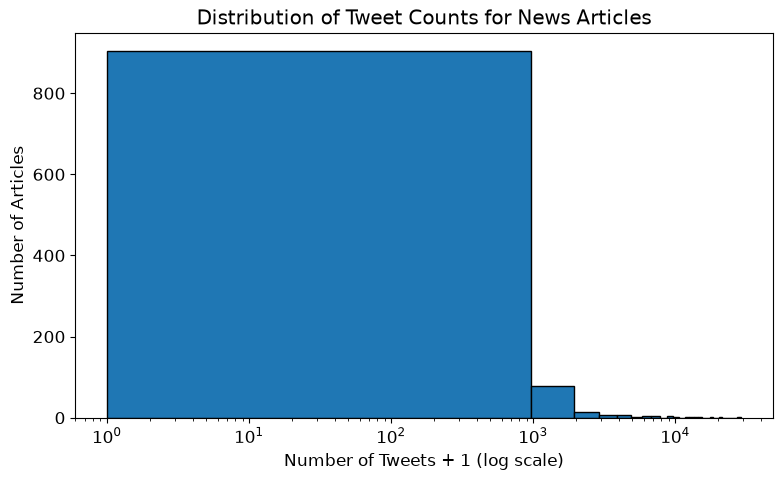

In [20]:
# Dravya: num_tweets histogram
plt.figure(figsize=(9, 5))

plt.hist(news_clean["num_tweets"] + 1, bins=30, edgecolor="black")
plt.xscale("log")

plt.title("Distribution of Tweet Counts for News Articles")
plt.xlabel("Number of Tweets + 1 (log scale)")
plt.ylabel("Number of Articles")

plt.show()

**num_tweets:** The distribution is strongly right-skewed. Most articles have relatively low tweet counts, while a small number of articles received thousands of tweets. The values have a large spread, with some clear high outliers reaching around 29,000 tweets.

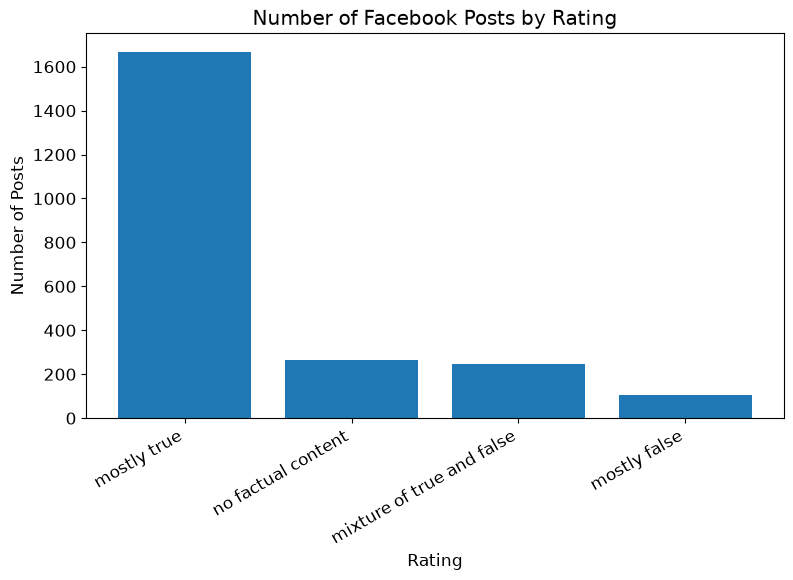

In [21]:
# Dravya: Facebook Rating counts
rating_counts = facebook["Rating"].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(rating_counts.index, rating_counts.values)

plt.title("Number of Facebook Posts by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Posts")

plt.xticks(rotation=30, ha="right")

plt.show()

**Facebook Rating:** The rating categories are not evenly distributed. Some ratings have many more posts than others, so there is a noticeable difference between the categories. Since Rating is categorical, there is no numerical center or skew like there is for tweet counts.

## 4. Relationships

### Plot 1 (Mahi): fake news share over time
**pct_fake:** Most days were around 5%, usually between 4% and 6%. The shape is balanced, not skewed. Outliers: Oct 15 was highest (8.3%) and Nov 9 was lowest (1.9%).

**N:** Most days had about 400,000 to 600,000 views. The shape is right-skewed because a few days had way more views. Those were big news days: election day (1.5 million), the day after (1.3 million), and two debate days (about 1 million).

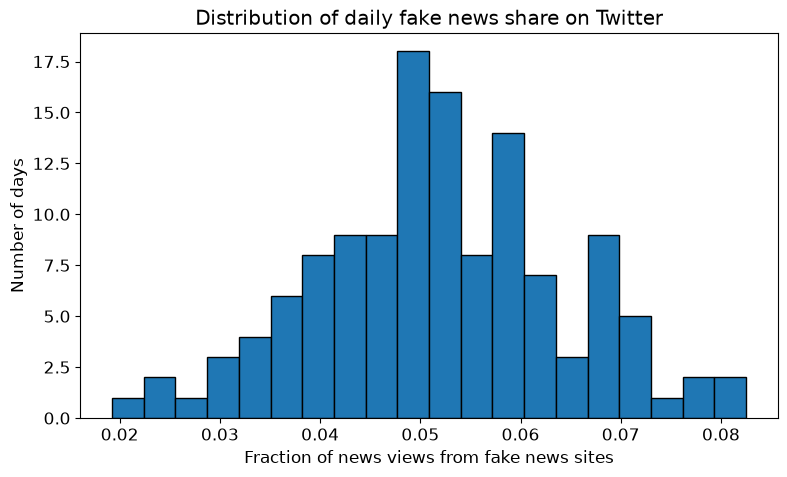

In [22]:
# Mahi: pct_fake histogram
plt.figure(figsize=(9, 5))
plt.hist(twitter_daily['pct_fake'], bins=20, edgecolor='black')
plt.title('Distribution of daily fake news share on Twitter')
plt.xlabel('Fraction of news views from fake news sites')
plt.ylabel('Number of days')
plt.show()


### Plot 2 (Dravya): tweets for fake vs real articles, compared with Facebook shares


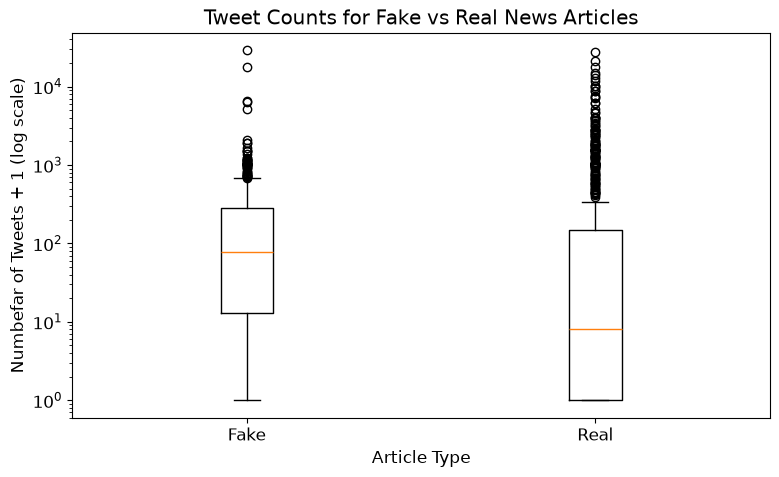

In [23]:
# Dravya: fake vs real tweet counts
fake_tweets = news_clean[news_clean["label"] == "fake"]["num_tweets"] + 1
real_tweets = news_clean[news_clean["label"] == "real"]["num_tweets"] + 1

plt.figure(figsize=(9, 5))

plt.boxplot(
    [fake_tweets, real_tweets],
    tick_labels=["Fake", "Real"]
)

plt.yscale("log")

plt.title("Tweet Counts for Fake vs Real News Articles")
plt.xlabel("Article Type")
plt.ylabel("Numbefar of Tweets + 1 (log scale)")

plt.show()

**So what:** The box plot compares how much fake and real articles were shared on Twitter. This helps us see whether fake news was generally shared more than real news.

**Expected or unexpected?:** The result was [expected/unexpected] based on which group has the higher median and spread.

**What next:** Next, we could compare the articles by topic to see if certain types of fake news get shared more than others.

### Plot 3 (Krish): website quality vs Twitter views
Here we join the Twitter website totals with the quality ratings (secondary dataset) on website name.

(534, 4)


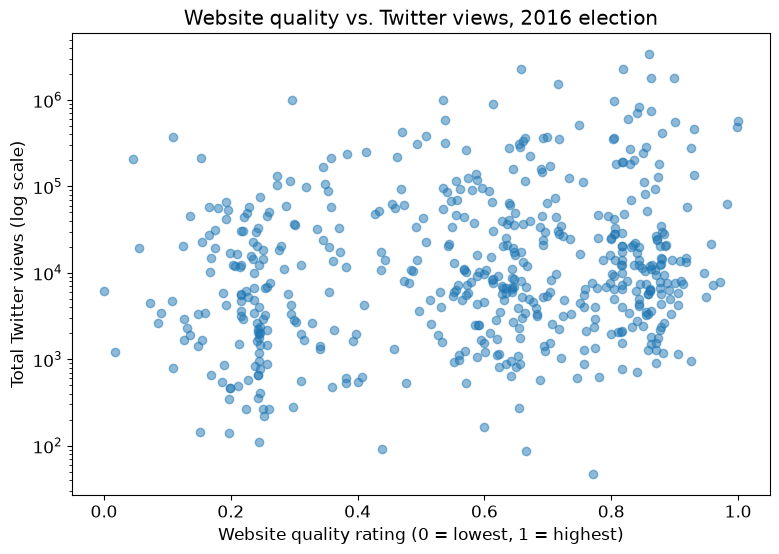

In [24]:
joined = twitter_sites.merge(ratings, left_on="website", right_on="domain")
print(joined.shape)

plt.figure(figsize=(9, 6))
plt.scatter(joined["pc1"], joined["N"], alpha=0.5)
plt.yscale("log")
plt.xlabel("Website quality rating (0 = lowest, 1 = highest)")
plt.ylabel("Total Twitter views (log scale)")
plt.title("Website quality vs. Twitter views, 2016 election")
plt.show()

In [25]:
# group websites into low / medium / high quality and compare
joined["quality"] = pd.cut(joined["pc1"], bins=[0, 0.4, 0.7, 1], labels=["low", "medium", "high"], include_lowest=True)
summary = joined.groupby("quality", observed=True)["N"].agg(["count", "median", "sum"])
summary["share_of_views_%"] = (summary["sum"] / summary["sum"].sum() * 100).round(1)
summary

,count,median,sum,share_of_views_%
quality,,,,
low,155,5304.0,4821462,11.4
medium,183,10187.0,13422483,31.8
high,196,11184.5,23972667,56.8


In [26]:
# correlation (spearman, because N is very skewed)
print("spearman correlation:", round(joined["pc1"].corr(joined["N"], method="spearman"), 2))

# the low-quality sites that still got lots of views
joined[joined["quality"] == "low"].sort_values("N", ascending=False).head(5)

spearman correlation: 0.17


,website,N,domain,pc1,quality
156,breitbart.com,1004415,breitbart.com,0.297175,low
205,thegatewaypundit.com,369875,thegatewaypundit.com,0.109375,low
67,dailymail.co.uk,235763,dailymail.co.uk,0.383861,low
304,americanthinker.com,215884,americanthinker.com,0.152500,low
63,politicususa.com,211021,politicususa.com,0.358451,low


**So what:** We expected low-quality sites to get more views, but it was the opposite. High-quality sites got 57% of all views and low-quality sites only 11%. The correlation is weak though (0.17), and a few low-quality sites were still huge, like breitbart.com with about 1 million views. So low-quality news was a small part overall but concentrated in a few big sites.

**Expected or unexpected?** Mostly unexpected. We thought "fake news spreads more" would show up here, but total views went mostly to mainstream sites.

**What next:** Total views depends on how many articles a site posts, so next we want to look at views per article. We could also split the sites by political side.

## 5. Revised research questions

1. **Does the typical fake article get shared more than the typical real one?** Changed because the median and mean gave opposite answers, so we need to say which one we mean.
2. **How did the fake news share on Twitter change over time?** because plot 1 showed the share went down on big news days and up on weekends, so the amount of total news seems to matter too.)*
3. **Is low-quality news concentrated in a few websites, and do they get more views per article?** Changed because plot 3 showed low-quality sites get fewer views overall, but a few of them are really big.